In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import imblearn

print("Toutes les bibliothèques sont installées !")

print("Pandas :", pd.__version__)
print("NumPy :", np.__version__)
print("Scikit-learn :", sklearn.__version__)

Toutes les bibliothèques sont installées !
Pandas : 3.1.0
NumPy : 2.5.4
Scikit-learn : 1.9.1


In [3]:
df = sns.load_dataset("titanic")

# Afficher les 5 premières lignes
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
# Nombre de lignes et de colonnes
print("Dimensions du dataset :", df.shape)

# Informations générales sur le dataset
df.info()

Dimensions du dataset : (891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [5]:
# Sélectionner les variables numériques
numerical_columns = df.select_dtypes(include=np.number).columns

print("Variables numériques :")
print(numerical_columns.tolist())

Variables numériques :
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']


In [6]:
# Sélectionner les variables catégorielles
categorical_columns = df.select_dtypes(
    include=["str", "category", "bool"]
).columns

print("Variables catégorielles :")
print(categorical_columns.tolist())

Variables catégorielles :
['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [7]:
# Identifier les valeurs manquantes
missing_values = df.isnull().sum()

print("Nombre de valeurs manquantes par colonne :")
print(missing_values)

Nombre de valeurs manquantes par colonne :
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [8]:
# Calculer le pourcentage des valeurs manquantes
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Afficher les résultats
print("Pourcentage des valeurs manquantes :")
print(missing_percentage.round(2))

Pourcentage des valeurs manquantes :
survived        0.00
pclass          0.00
sex             0.00
age            19.87
sibsp           0.00
parch           0.00
fare            0.00
embarked        0.22
class           0.00
who             0.00
adult_male      0.00
deck           77.22
embark_town     0.22
alive           0.00
alone           0.00
dtype: float64


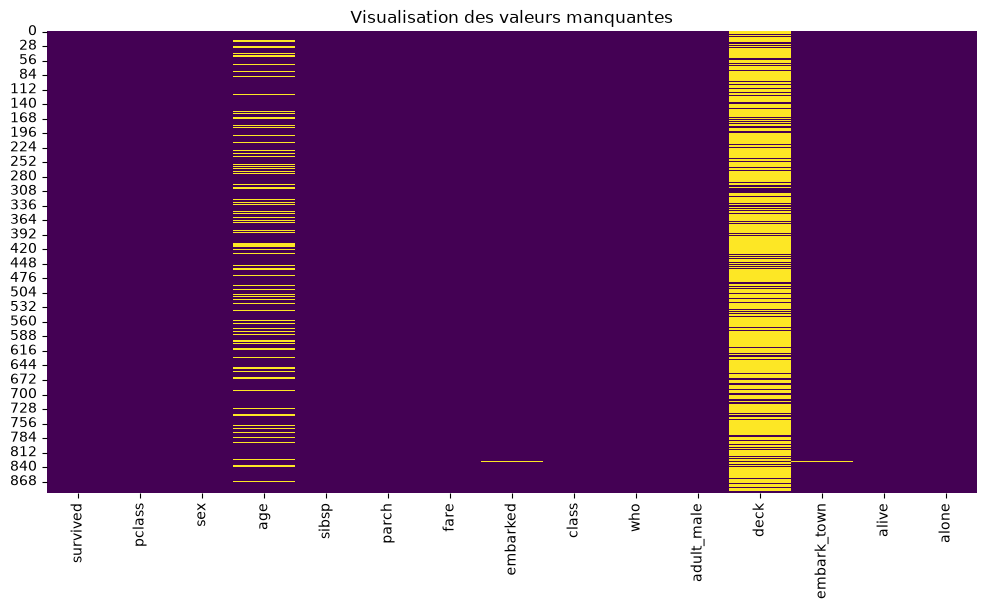

In [9]:
plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), cbar=False, cmap="viridis")

plt.title("Visualisation des valeurs manquantes")
plt.show()

In [10]:
age_median = df["age"].median()

print("Médiane de age :", age_median)

df["age"] = df["age"].fillna(age_median)

# Vérifier le résultat
print("Valeurs manquantes dans age :", df["age"].isnull().sum())

Médiane de age : 28.0
Valeurs manquantes dans age : 0


In [11]:
print("Mode de embarked :", df["embarked"].mode()[0])

df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])


print("Mode de embark_town :", df["embark_town"].mode()[0])

df["embark_town"] = df["embark_town"].fillna(df["embark_town"].mode()[0])

Mode de embarked : S
Mode de embark_town : Southampton


In [12]:
print(df[["age", "embarked", "embark_town"]].isnull().sum())

age            0
embarked       0
embark_town    0
dtype: int64


In [13]:
deck_missing = (df["deck"].isnull().sum() / len(df)) * 100

print("Pourcentage de valeurs manquantes :", round(deck_missing, 2), "%")

Pourcentage de valeurs manquantes : 77.22 %


In [14]:
df = df.drop(columns=["deck"])

print("La colonne deck a été supprimée.")

La colonne deck a été supprimée.


In [15]:
print("Dimensions après suppression :", df.shape)

print("Valeurs manquantes restantes :")
print(df.isnull().sum())

Dimensions après suppression : (891, 14)
Valeurs manquantes restantes :
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


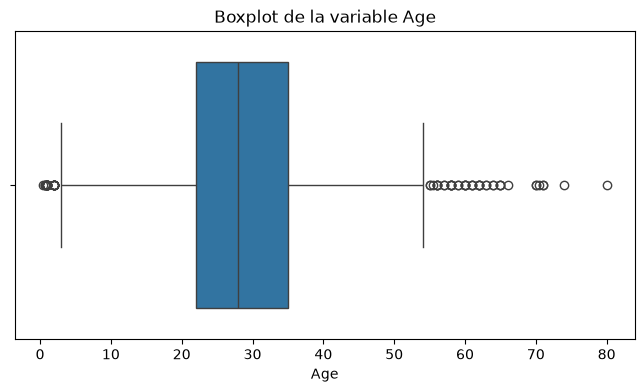

In [16]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["age"])

plt.title("Boxplot de la variable Age")
plt.xlabel("Age")

plt.show()

In [17]:
Q1 = df["age"].quantile(0.25)
Q3 = df["age"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1 :", Q1)
print("Q3 :", Q3)
print("IQR :", IQR)

print("Limite inférieure :", lower_bound)
print("Limite supérieure :", upper_bound)

Q1 : 22.0
Q3 : 35.0
IQR : 13.0
Limite inférieure : 2.5
Limite supérieure : 54.5


In [18]:
outliers = df[
    (df["age"] < lower_bound) |
    (df["age"] > upper_bound)
]

print("Nombre d'Outliers :", len(outliers))

print("Valeurs aberrantes :")
print(outliers["age"].sort_values().tolist())

Nombre d'Outliers : 66
Valeurs aberrantes :
[0.42, 0.67, 0.75, 0.75, 0.83, 0.83, 0.92, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 55.0, 55.0, 55.5, 56.0, 56.0, 56.0, 56.0, 57.0, 57.0, 58.0, 58.0, 58.0, 58.0, 58.0, 59.0, 59.0, 60.0, 60.0, 60.0, 60.0, 61.0, 61.0, 61.0, 62.0, 62.0, 62.0, 62.0, 63.0, 63.0, 64.0, 64.0, 65.0, 65.0, 65.0, 66.0, 70.0, 70.0, 70.5, 71.0, 71.0, 74.0, 80.0]


In [19]:
df_outliers = df.copy()

median_age = df_outliers["age"].median()

df_outliers.loc[
    (df_outliers["age"] < lower_bound) |
    (df_outliers["age"] > upper_bound),
    "age"
] = median_age

print("Médiane :", median_age)

Médiane : 28.0


In [20]:
remaining_outliers = df_outliers[
    (df_outliers["age"] < lower_bound) |
    (df_outliers["age"] > upper_bound)
]

print("Outliers avant traitement :", len(outliers))
print("Outliers après traitement :", len(remaining_outliers))

Outliers avant traitement : 66
Outliers après traitement : 0


In [21]:
df_encoded = pd.get_dummies(
    df_outliers,
    columns=["sex"],
    dtype=int
)

# Afficher les premières lignes
df_encoded.head()

,survived,pclass,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone,sex_female,sex_male
0,0,3,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False,0,1
1,1,1,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False,1,0
2,1,3,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True,1,0
3,1,1,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False,1,0
4,0,3,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True,0,1


In [22]:
from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder()

df_encoded["pclass_encoded"] = encoder.fit_transform(
    df_encoded[["pclass"]]
)

# Afficher les résultats
print(df_encoded[["pclass", "pclass_encoded"]].head(10))

   pclass  pclass_encoded
0       3             2.0
1       1             0.0
2       3             2.0
3       1             0.0
4       3             2.0
5       3             2.0
6       1             0.0
7       3             2.0
8       3             2.0
9       2             1.0


In [27]:
from sklearn.preprocessing import MinMaxScaler

df_minmax = df_encoded.copy()

scaler = MinMaxScaler()

df_minmax[numerical_columns] = scaler.fit_transform(
    df_minmax[numerical_columns]
)

df_minmax.head()

,survived,pclass,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone,sex_female,sex_male,pclass_encoded
0,0.0,1.0,0.372549,0.125,0.0,0.014151,S,Third,man,True,Southampton,no,False,0.0,1.0,1.0
1,1.0,0.0,0.686275,0.125,0.0,0.139136,C,First,woman,False,Cherbourg,yes,False,1.0,0.0,0.0
2,1.0,1.0,0.450980,0.000,0.0,0.015469,S,Third,woman,False,Southampton,yes,True,1.0,0.0,1.0
3,1.0,0.0,0.627451,0.125,0.0,0.103644,S,First,woman,False,Southampton,yes,False,1.0,0.0,0.0
4,0.0,1.0,0.627451,0.000,0.0,0.015713,S,Third,man,True,Southampton,no,True,0.0,1.0,1.0


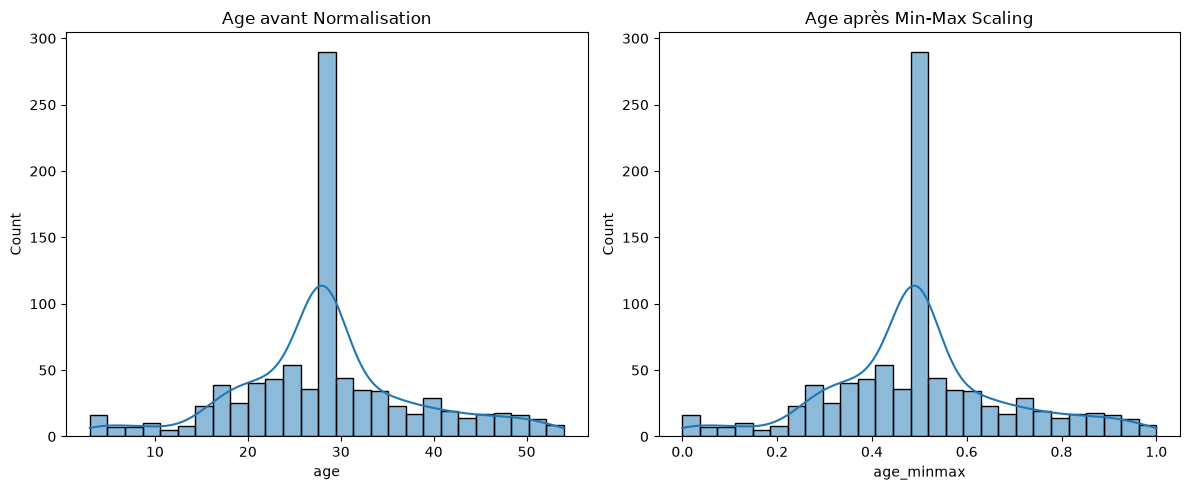

In [25]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df_encoded["age"], kde=True)
plt.title("Age avant Normalisation")

plt.subplot(1, 2, 2)
sns.histplot(df_minmax["age_minmax"], kde=True)
plt.title("Age après Min-Max Scaling")

plt.tight_layout()
plt.show()

In [29]:
print("Minimum :")
print(df_minmax[numerical_columns].min())

print("\nMaximum :")
print(df_minmax[numerical_columns].max())

Minimum :
survived          0.0
pclass            0.0
age               0.0
sibsp             0.0
parch             0.0
fare              0.0
sex_female        0.0
sex_male          0.0
pclass_encoded    0.0
dtype: float64

Maximum :
survived          1.0
pclass            1.0
age               1.0
sibsp             1.0
parch             1.0
fare              1.0
sex_female        1.0
sex_male          1.0
pclass_encoded    1.0
dtype: float64


In [30]:
print("Avant normalisation :")
print(df_encoded[numerical_columns].head())

print("\nAprès normalisation :")
print(df_minmax[numerical_columns].head())

Avant normalisation :
   survived  pclass   age  sibsp  parch     fare  sex_female  sex_male  \
0         0       3  22.0      1      0   7.2500           0         1   
1         1       1  38.0      1      0  71.2833           1         0   
2         1       3  26.0      0      0   7.9250           1         0   
3         1       1  35.0      1      0  53.1000           1         0   
4         0       3  35.0      0      0   8.0500           0         1   

   pclass_encoded  
0             2.0  
1             0.0  
2             2.0  
3             0.0  
4             2.0  

Après normalisation :
   survived  pclass       age  sibsp  parch      fare  sex_female  sex_male  \
0       0.0     1.0  0.372549  0.125    0.0  0.014151         0.0       1.0   
1       1.0     0.0  0.686275  0.125    0.0  0.139136         1.0       0.0   
2       1.0     1.0  0.450980  0.000    0.0  0.015469         1.0       0.0   
3       1.0     0.0  0.627451  0.125    0.0  0.103644         1.0       0.

In [31]:
from sklearn.preprocessing import StandardScaler

df_standard = df_encoded.copy()

numerical_columns = df_standard.select_dtypes(include=np.number).columns

scaler = StandardScaler()

df_standard[numerical_columns] = scaler.fit_transform(
    df_standard[numerical_columns]
)

df_standard.head()

,survived,pclass,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone,sex_female,sex_male,pclass_encoded
0,-0.789272,0.827377,-0.661724,0.432793,-0.473674,-0.502445,S,Third,man,True,Southampton,no,False,-0.737695,0.737695,0.827377
1,1.266990,-1.566107,0.972921,0.432793,-0.473674,0.786845,C,First,woman,False,Cherbourg,yes,False,1.355574,-1.355574,-1.566107
2,1.266990,0.827377,-0.253063,-0.474545,-0.473674,-0.488854,S,Third,woman,False,Southampton,yes,True,1.355574,-1.355574,0.827377
3,1.266990,-1.566107,0.666425,0.432793,-0.473674,0.420730,S,First,woman,False,Southampton,yes,False,1.355574,-1.355574,-1.566107
4,-0.789272,0.827377,0.666425,-0.474545,-0.473674,-0.486337,S,Third,man,True,Southampton,no,True,-0.737695,0.737695,0.827377


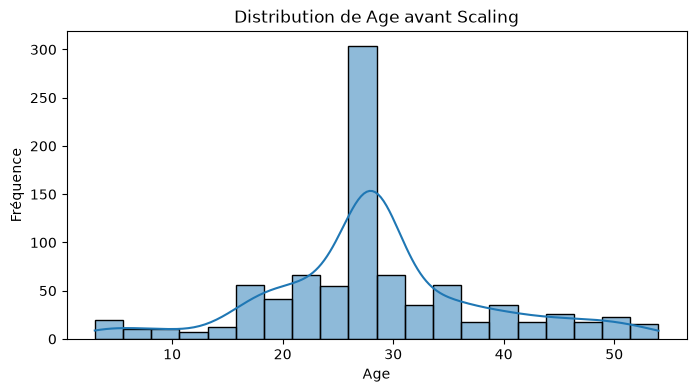

In [32]:
plt.figure(figsize=(8, 4))

sns.histplot(df_encoded["age"], bins=20, kde=True)

plt.title("Distribution de Age avant Scaling")
plt.xlabel("Age")
plt.ylabel("Fréquence")

plt.show()

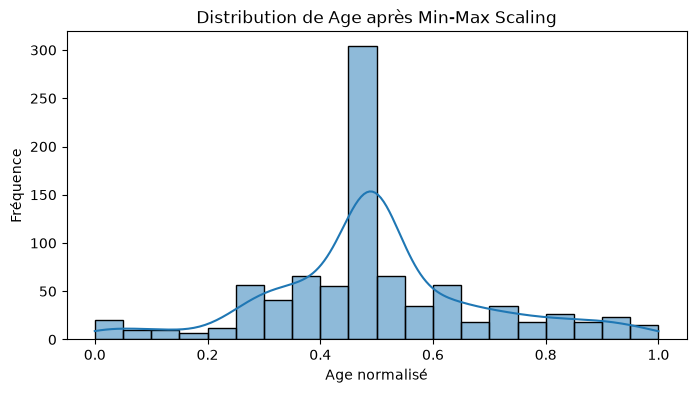

In [33]:
plt.figure(figsize=(8, 4))

sns.histplot(df_minmax["age"], bins=20, kde=True)

plt.title("Distribution de Age après Min-Max Scaling")
plt.xlabel("Age normalisé")
plt.ylabel("Fréquence")

plt.show()

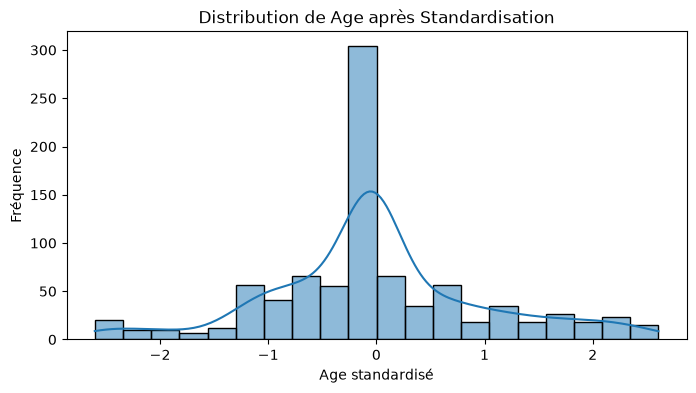

In [34]:
plt.figure(figsize=(8, 4))

sns.histplot(df_standard["age"], bins=20, kde=True)

plt.title("Distribution de Age après Standardisation")
plt.xlabel("Age standardisé")
plt.ylabel("Fréquence")

plt.show()

In [35]:
print(df_encoded["survived"].value_counts())

survived
0    549
1    342
Name: count, dtype: int64


In [36]:
print(df_encoded["survived"].value_counts(normalize=True) * 100)

survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


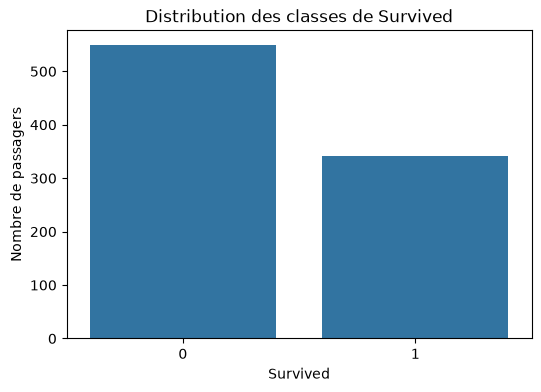

In [37]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df_encoded, x="survived")

plt.title("Distribution des classes de Survived")
plt.xlabel("Survived")
plt.ylabel("Nombre de passagers")

plt.show()

In [38]:
from imblearn.under_sampling import RandomUnderSampler

X = df_encoded.drop(columns=["survived"])
y = df_encoded["survived"]

rus = RandomUnderSampler(random_state=42)
X_under, y_under = rus.fit_resample(X, y)

print(y_under.value_counts())

survived
0    342
1    342
Name: count, dtype: int64


In [39]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_over, y_over = smote.fit_resample(X, y)

print(y_over.value_counts())

ValueError: could not convert string to float: 'S'

In [40]:
categorical_cols = X.select_dtypes(
    include=["str", "object", "category", "bool"]
).columns

print(categorical_cols.tolist())

['embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive', 'alone']


In [41]:
X_numeric = pd.get_dummies(X, dtype=int)

print(X_numeric.select_dtypes(
    include=["str", "object", "category", "bool"]
).columns.tolist())

['adult_male', 'alone']


In [42]:
X_numeric = pd.get_dummies(X, dtype=int)

bool_cols = X_numeric.select_dtypes(include=["bool"]).columns

X_numeric[bool_cols] = X_numeric[bool_cols].astype(int)

print(X_numeric.select_dtypes(
    include=["str", "object", "category", "bool"]
).columns.tolist())

[]


In [43]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_over, y_over = smote.fit_resample(X_numeric, y)

print(y_over.value_counts())

survived
0    549
1    549
Name: count, dtype: int64


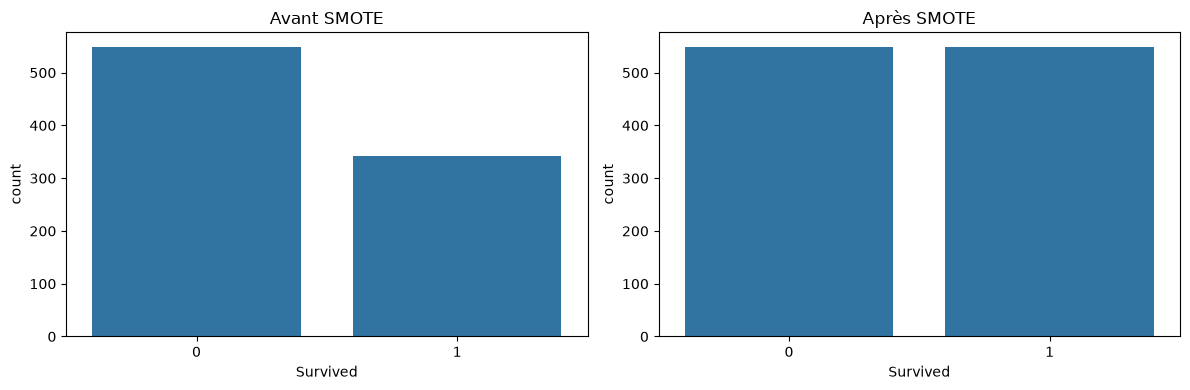

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x=y, ax=axes[0])
axes[0].set_title("Avant SMOTE")
axes[0].set_xlabel("Survived")

sns.countplot(x=y_over, ax=axes[1])
axes[1].set_title("Après SMOTE")
axes[1].set_xlabel("Survived")

plt.tight_layout()
plt.show()